## Time Series Forecasting module

In [106]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from configs.system import project_dir

In [107]:
p_dir = project_dir()

data_dir = p_dir.FEATURED_DIR
dataset_path = data_dir/'featured_dataset.csv'

In [108]:
df = pd.read_csv(dataset_path,index_col=0)
df.sample(2)

,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,...,Duration,Demand,StartMonth,StartWeek,EndMonth,EndWeek,DemandPerMonth,StartDayOfWeek,DemandPerDay,Shift
39623,0,350,0,apartment,0,2021-11-01,17:24:01,2021-11-01,20:46:12,2021-11-01 17:24:00,...,202,23.2,11,0,11,0,71741.55,Monday,17.35,Night
27935,0,204,1,company,0,2022-06-09,23:54:07,2022-06-10,01:16:32,2022-06-09 23:54:00,...,82,9.7,6,3,6,4,117564.42,Thursday,17.62,Night


In [109]:
df.info()

<class 'pandas.DataFrame'>
Index: 72826 entries, 0 to 72855
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   UserID          72826 non-null  int64  
 1   ChargerID       72826 non-null  int64  
 2   ChargerCompany  72826 non-null  int64  
 3   Location        72826 non-null  str    
 4   ChargerType     72826 non-null  int64  
 5   StartDay        72826 non-null  str    
 6   StartTime       72826 non-null  str    
 7   EndDay          72826 non-null  str    
 8   EndTime         72826 non-null  str    
 9   StartDatetime   72826 non-null  str    
 10  EndDatetime     72826 non-null  str    
 11  Duration        72826 non-null  int64  
 12  Demand          72826 non-null  float64
 13  StartMonth      72826 non-null  int64  
 14  StartWeek       72826 non-null  int64  
 15  EndMonth        72826 non-null  int64  
 16  EndWeek         72826 non-null  int64  
 17  DemandPerMonth  72826 non-null  float64
 18  St

In [110]:
df_ = df[['StartDatetime','Demand']]
df_ = df_.set_index('StartDatetime')

In [111]:
df_.index = pd.to_datetime(df_.index)
df_ = df_.sort_index()
# df_['StartDay'] = pd.to_datetime(df_.index).day

In [112]:
df_


,Demand
StartDatetime,
2021-09-30 17:14:00,27.68
2021-09-30 18:22:00,55.13
2021-09-30 18:57:00,38.45
2021-09-30 19:52:00,30.17
2021-09-30 20:48:00,47.00
...,...
2022-09-30 21:49:00,6.00
2022-09-30 22:10:00,15.79
2022-09-30 22:31:00,5.83


In [113]:
train = df_[df_.index < '2022-07-31']
test = df_[df_.index >= '2022-07-31']

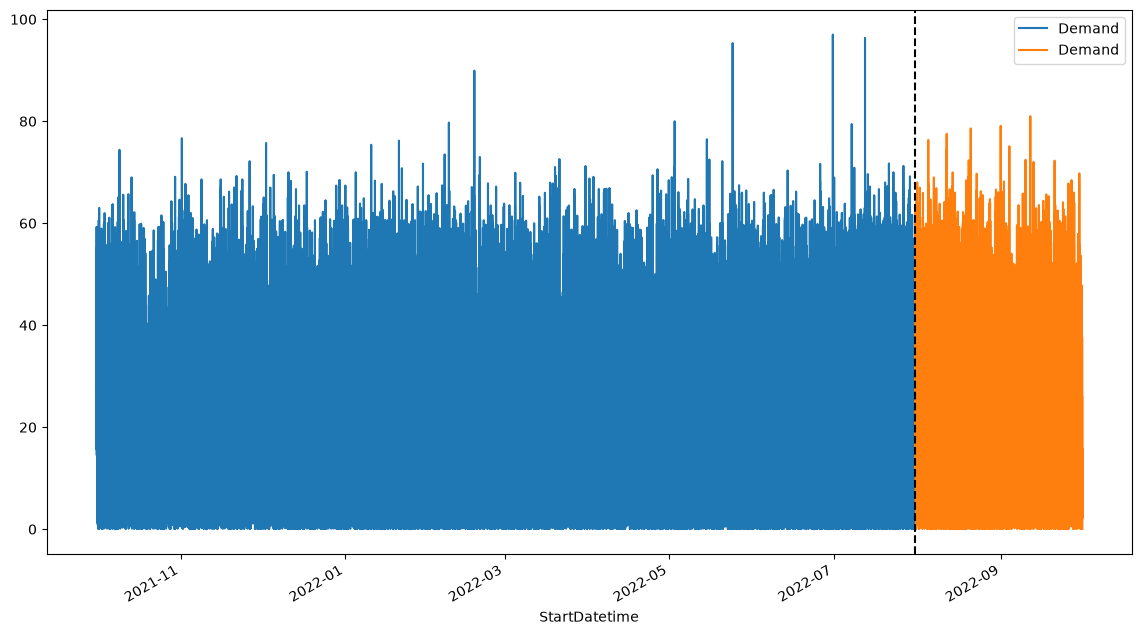

In [114]:
fig, ax = plt.subplots(figsize=(14,8))
train.plot(ax=ax,label='Train set')
test.plot(ax=ax,label='Test set')
plt.axvline('2022-07-31',color='black',ls='--')
plt.show()

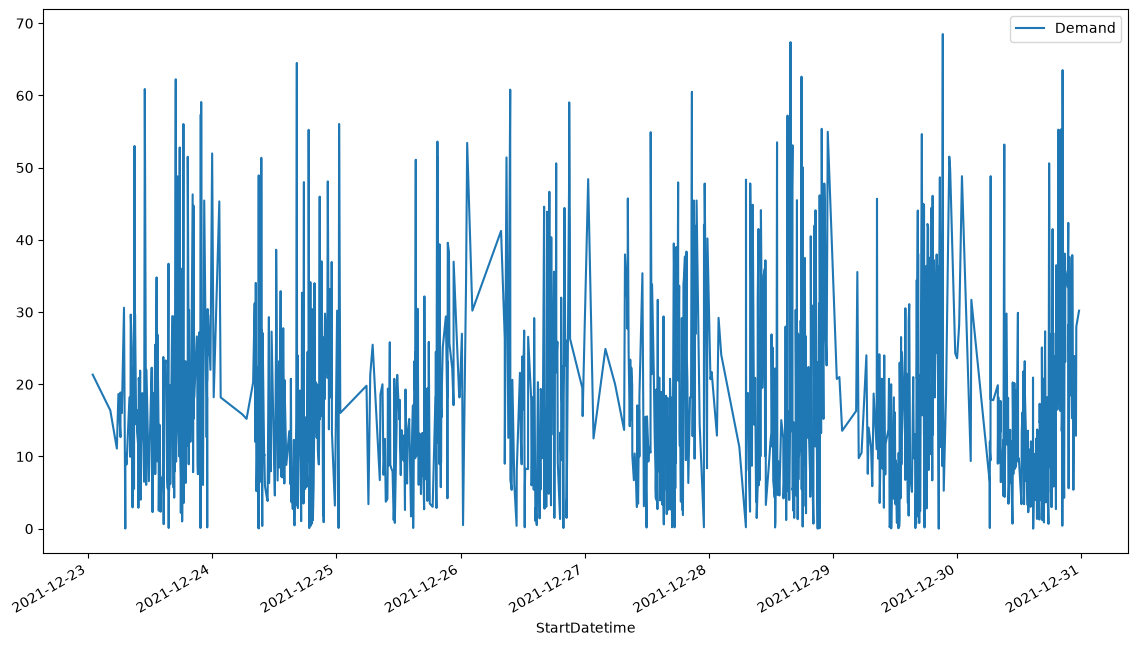

In [115]:
# visualize the weekly pattern
df_.loc[(df_.index > '23-12-2021') & (df_.index < '31-12-2021')].plot(
    figsize=(14,8)
)
plt.show()

In [116]:
df_['Hour'] = df_.index.hour
df_['Month'] = df_.index.month
df_['DayofWeek'] = df_.index.dayofweek
df_['Is_weekend'] = df_.index.dayofweek >= 5
# df_['Date'] = pd.to_datetime(df_.index).dt.day
# df_.index = pd.to_datetime(df_.index).date

In [117]:
y = df_.pop('Demand')

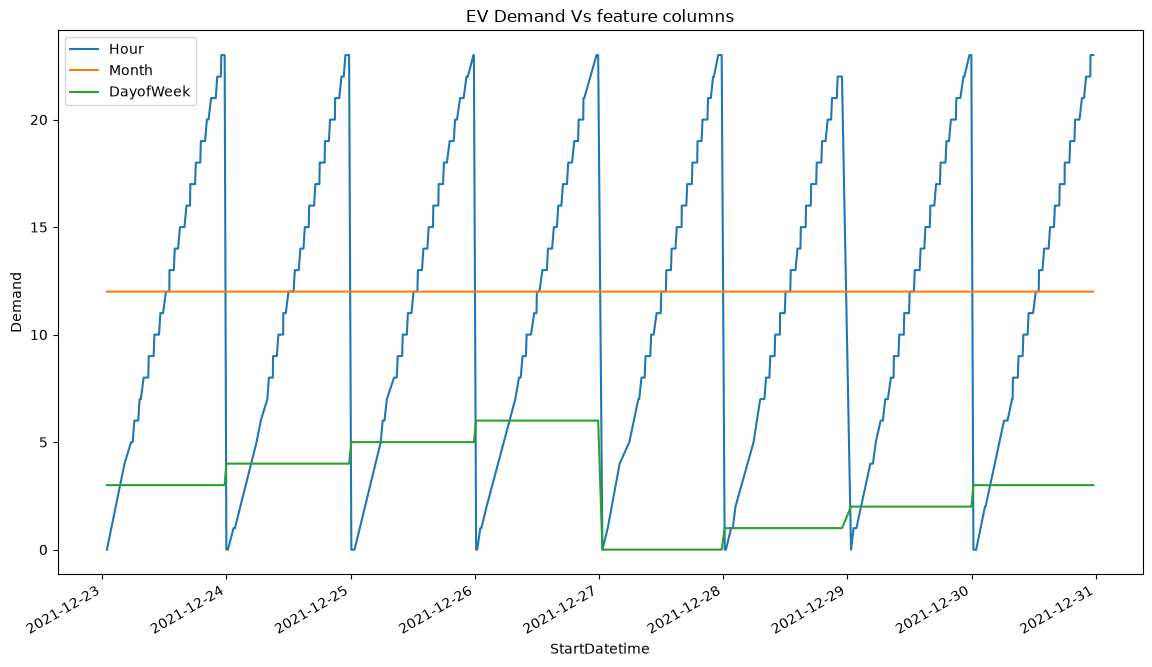

In [118]:
# df_.index = pd.to_datetime(df_.index)

df_.loc[
    (df_.index > '2021-12-23') &
    (df_.index < '2021-12-31')
].plot(figsize=(14, 8))

plt.title('EV Demand Vs feature columns')
plt.ylabel('Demand')
# plt.legend()
plt.show()